# 第六轮主实验：遗漏历史、排名轨迹与关键分

34项新配置，383项输入；仍用33,833条拟合目标与完整2,588场2023验证目标。所有2023结果属于反复使用样本上的探索，2024–2025最终测试未打开。没有市场价格输入，也没有放宽T−21历史截止。

## 开发期选择及2023结果

- 2022流程门槛：原参考准确率67.1282%，早期选中流程67.5237%，增幅+0.396个百分点，要求至少0.5个百分点且loss护栏通过。结论：`retain_round4`。
- 正式推荐：`previous_probability_recommendation`。pooled开发折选择的探索比较：`accuracy_grid_blend`，2023正确**1693/2588 = 65.42%**，log loss **0.60774**。
- 相对第五轮冻结探索组合：纠正64场，同时新错86场，净增-22场；准确率差的条件日期块区间为[-1.679, -0.040]个百分点。该区间未覆盖全部搜索不确定性。
- 本表最高观察准确率`previous_round5_exploration`为66.27%；最低观察loss`previous_round5_best_loss`为0.60645。这些事后排序不改写冻结选择。
- 70%需要正确1,812场，探索比较仍差119场。

| 模型 | 正确数/2588 | Accuracy | Log loss ↓ | Brier ↓ |
| --- | ---: | ---: | ---: | ---: |
| `previous_round5_exploration` | 1715 | 66.27% | 0.60987 | 0.21166 |
| `previous_round5_best_loss` | 1706 | 65.92% | 0.60645 | 0.21032 |
| `r6_base_spline_C0.01` | 1704 | 65.84% | 0.60751 | 0.21077 |
| `r6_all_spline_C0.01` | 1702 | 65.77% | 0.60800 | 0.21103 |
| `r6_trajectory_linear_C0.003` | 1698 | 65.61% | 0.60745 | 0.21089 |
| `r6_all_linear_C0.01` | 1698 | 65.61% | 0.60797 | 0.21108 |
| `r6_trajectory_spline_C0.003` | 1697 | 65.57% | 0.60724 | 0.21075 |
| `previous_probability_recommendation` | 1696 | 65.53% | 0.60941 | 0.21149 |
| `accuracy_grid_blend` | 1693 | 65.42% | 0.60774 | 0.21094 |
| `r6_combined_spline_C0.003` | 1692 | 65.38% | 0.60844 | 0.21126 |
| `r6_base_linear_C0.003` | 1691 | 65.34% | 0.60758 | 0.21088 |
| `r6_combined_cat_d6` | 1690 | 65.30% | 0.61319 | 0.21313 |
| `r6_combined_linear_C0.003` | 1689 | 65.26% | 0.60863 | 0.21139 |
| `r6_extended_linear_C0.003` | 1688 | 65.22% | 0.60794 | 0.21101 |
| `r6_extended_spline_C0.003` | 1687 | 65.19% | 0.60777 | 0.21090 |
| `r6_breakpoint_spline_C0.003` | 1684 | 65.07% | 0.60828 | 0.21116 |
| `r6_breakpoint_linear_C0.003` | 1683 | 65.03% | 0.60845 | 0.21127 |
| `rank_reference` | 1640 | 63.37% | 0.62980 | 0.22016 |

## 匹配信息对照

每块在相同学习器、C及half-life下与275项旧核心特征比较，计6个匹配对照。下表是pooled2020–2022结果的描述均值，不能当独立样本做显著性检验。完整各年差值在`matched_information_controls.csv`。

| 加入信息 | Accuracy改善的对照数 | 平均Accuracy变化（百分点） | 平均loss降低 |
| --- | ---: | ---: | ---: |
| breakpoint | 1/6 | -0.057 | -0.00023 |
| combined | 1/6 | -0.073 | +0.00050 |
| extended | 1/6 | -0.185 | -0.00032 |
| trajectory | 4/6 | +0.125 | +0.00099 |

新增历史评级包含相同算法的旧历史控制；允许赛事与排除项详见来源审计。排名轨迹只用2006以来、每场T−21以前的可见记录，同日冲突快照不使用，不能称官方生涯最高排名。BP/保发残差固定收缩，并不被解释成心理能力或因果效应。

## 复跑与限制

先复现前五轮，然后运行`python -m scripts.train_round6`及`python -m scripts.report_round6`。本报告只读取已保存结果，不改变模型。使用`python -m scripts.train_round6 --predict-features path/to/features.csv`重载冻结模型，需要全部383项冻结输入。大特征表和本地joblib按固定来源重建，不提交Git。

跨级别监督迁移是单独的匹配实验，见[迁移报告](transfer/report_summary.md)；跨来源标签审计见[独立记录](source_audit.md)。既有市场结果来自更晚信息条件，不与本轮历史算法增益混为一谈。[实验协议](../../docs/research/round6_protocol.md) · [机器选择记录](frozen_selection.json) · [独立重载审计](artifact_audit.json)。


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
OUT = ROOT / 'results/round6'
comparison = pd.read_csv(OUT / 'validation_comparison.csv')
display(comparison)

,model,recommended,matches,correct,accuracy,mean_log_loss,brier
0,previous_round5_exploration,False,2588,1715,0.662674,0.609871,0.211658
1,previous_round5_best_loss,False,2588,1706,0.659196,0.606453,0.210323
2,r6_base_spline_C0.01,False,2588,1704,0.658423,0.607506,0.210770
3,r6_all_spline_C0.01,False,2588,1702,0.657651,0.607997,0.211030
4,r6_trajectory_linear_C0.003,False,2588,1698,0.656105,0.607455,0.210885
5,r6_all_linear_C0.01,False,2588,1698,0.656105,0.607974,0.211081
6,r6_trajectory_spline_C0.003,False,2588,1697,0.655719,0.607237,0.210755
7,previous_probability_recommendation,True,2588,1696,0.655332,0.609407,0.211493
8,accuracy_grid_blend,False,2588,1693,0.654173,0.607740,0.210940
9,r6_combined_spline_C0.003,False,2588,1692,0.653787,0.608441,0.211264


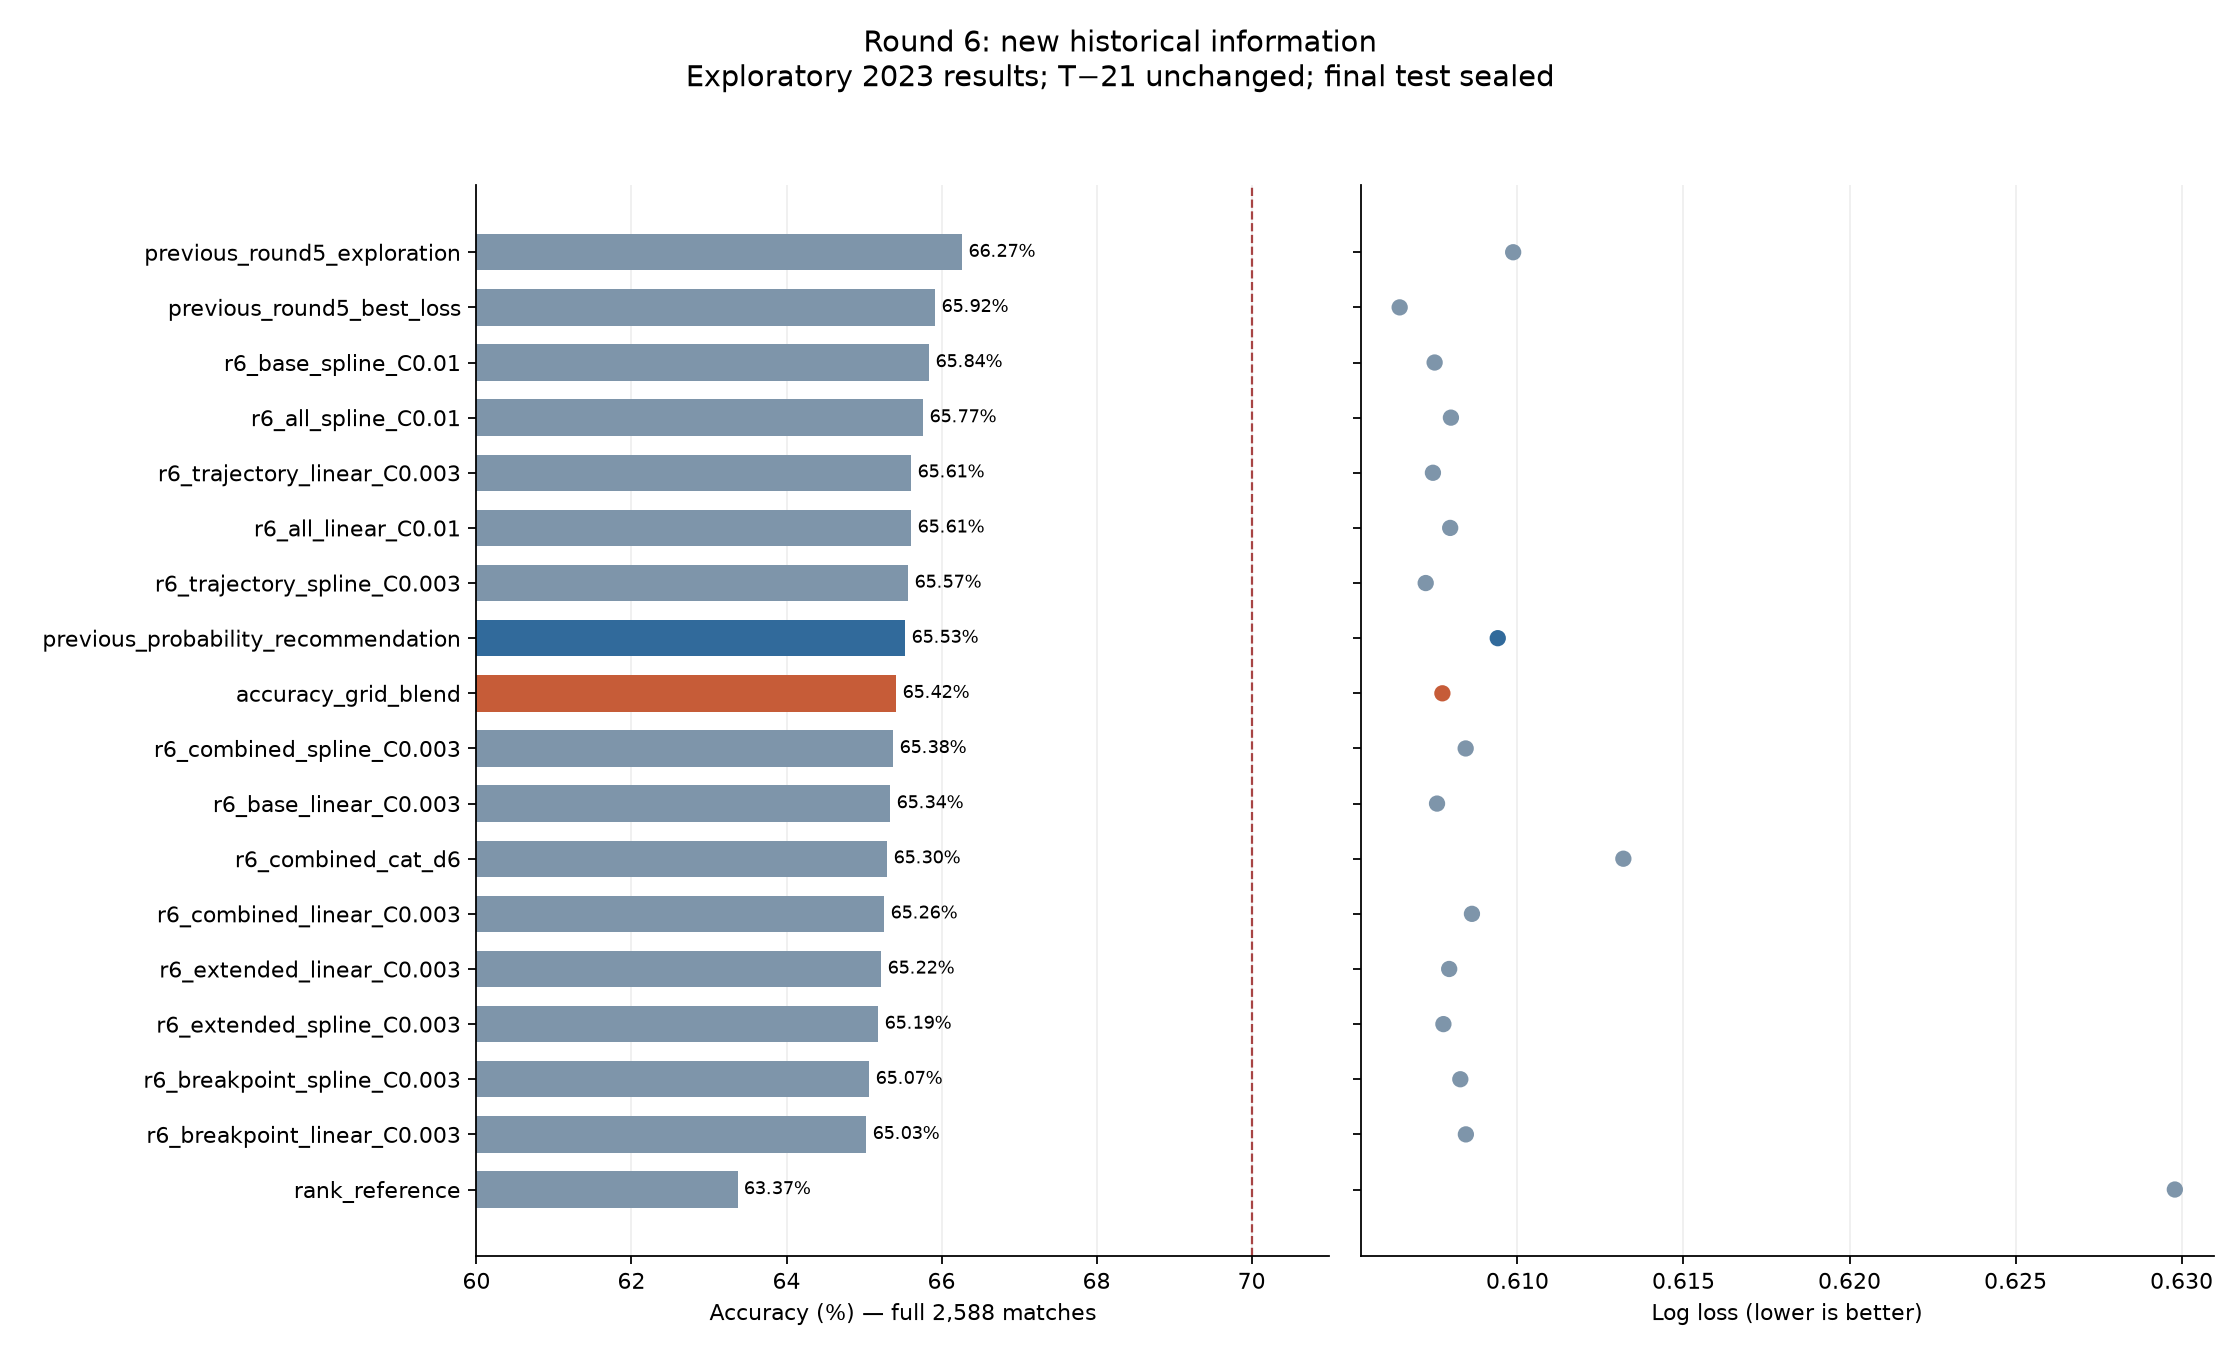

In [2]:
display(Image(filename=str(OUT / 'round6_comparison.png')))

In [3]:
display(pd.read_csv(OUT / 'matched_information_controls.csv'))

,feature_block,learner,C,base,candidate,accuracy_gain,log_loss_reduction,2020_accuracy_gain,2020_log_loss_reduction,2021_accuracy_gain,2021_log_loss_reduction,2022_accuracy_gain,2022_log_loss_reduction
0,extended,linear,0.003,r6_base_linear_C0.003,r6_extended_linear_C0.003,-0.003752,-0.000239,-0.002471,0.000024,-0.003350,-0.000097,-0.004747,-0.000499
1,extended,linear,0.010,r6_base_linear_C0.01,r6_extended_linear_C0.01,-0.002610,-0.000354,-0.004942,0.000138,0.000000,-0.000210,-0.003956,-0.000726
2,extended,linear,0.030,r6_base_linear_C0.03,r6_extended_linear_C0.03,-0.003915,-0.000361,-0.004942,0.000551,-0.004188,-0.000323,-0.003165,-0.000834
3,extended,spline,0.003,r6_base_spline_C0.003,r6_extended_spline_C0.003,0.000653,-0.000240,0.004119,0.000052,-0.000838,-0.000111,0.000396,-0.000501
4,extended,spline,0.010,r6_base_spline_C0.01,r6_extended_spline_C0.01,-0.001468,-0.000325,0.000824,0.000320,-0.002094,-0.000204,-0.001978,-0.000751
5,extended,spline,0.030,r6_base_spline_C0.03,r6_extended_spline_C0.03,0.000000,-0.000395,-0.001647,0.000548,0.000000,-0.000371,0.000791,-0.000871
6,trajectory,linear,0.003,r6_base_linear_C0.003,r6_trajectory_linear_C0.003,-0.000163,0.001139,-0.004119,0.002303,0.004606,0.002167,-0.002769,-0.000391
7,trajectory,linear,0.010,r6_base_linear_C0.01,r6_trajectory_linear_C0.01,0.001305,0.000887,-0.001647,0.002839,0.005863,0.001653,-0.001582,-0.000775
8,trajectory,linear,0.030,r6_base_linear_C0.03,r6_trajectory_linear_C0.03,-0.000816,0.000246,-0.000824,0.003163,0.003350,0.000317,-0.004747,-0.001221
9,trajectory,spline,0.003,r6_base_spline_C0.003,r6_trajectory_spline_C0.003,0.004078,0.001361,0.002471,0.002175,0.007956,0.002608,0.001187,-0.000208


In [4]:
frozen = json.loads((OUT / 'frozen_selection.json').read_text())
print(json.dumps(frozen, indent=2))

{
  "round": 6,
  "recommendation": "previous_probability_recommendation",
  "procedure_gate": {
    "procedure": "retain_round4",
    "early_selection": {
      "choice": "accuracy_grid_blend",
      "best_single": "r6_trajectory_spline_C0.003",
      "selected_by_family": {
        "all_linear": "r6_all_linear_C0.01",
        "all_spline": "r6_all_spline_C0.01",
        "base_linear": "r6_base_linear_C0.003",
        "base_spline": "r6_base_spline_C0.01",
        "breakpoint_linear": "r6_breakpoint_linear_C0.003",
        "breakpoint_spline": "r6_breakpoint_spline_C0.003",
        "combined_catboost": "r6_combined_cat_d6",
        "combined_linear": "r6_combined_linear_C0.003",
        "combined_spline": "r6_combined_spline_C0.003",
        "extended_linear": "r6_extended_linear_C0.003",
        "extended_spline": "r6_extended_spline_C0.003",
        "previous_reference": "previous_probability_recommendation",
        "trajectory_linear": "r6_trajectory_linear_C0.003",
        "traje